In [161]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

AUFGABE 1: AUFNAHME UND ANALYSE EINES GRAUWERTKEILES

Einlesen und Darstellung des Originalbildes

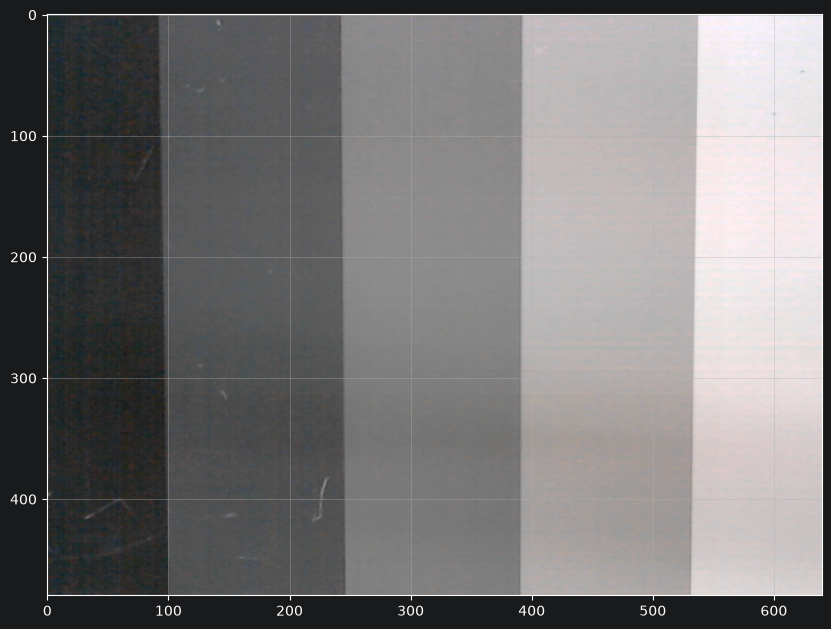

In [162]:
gray = cv2.imread("data/Grauwertkeil/gray.png")

plt.figure(figsize = (10,10))
plt.imshow(gray, cmap = "gray")
plt.grid()
plt.show()

Ausschneiden und Darstellung der einzelnen Grauwertstufen

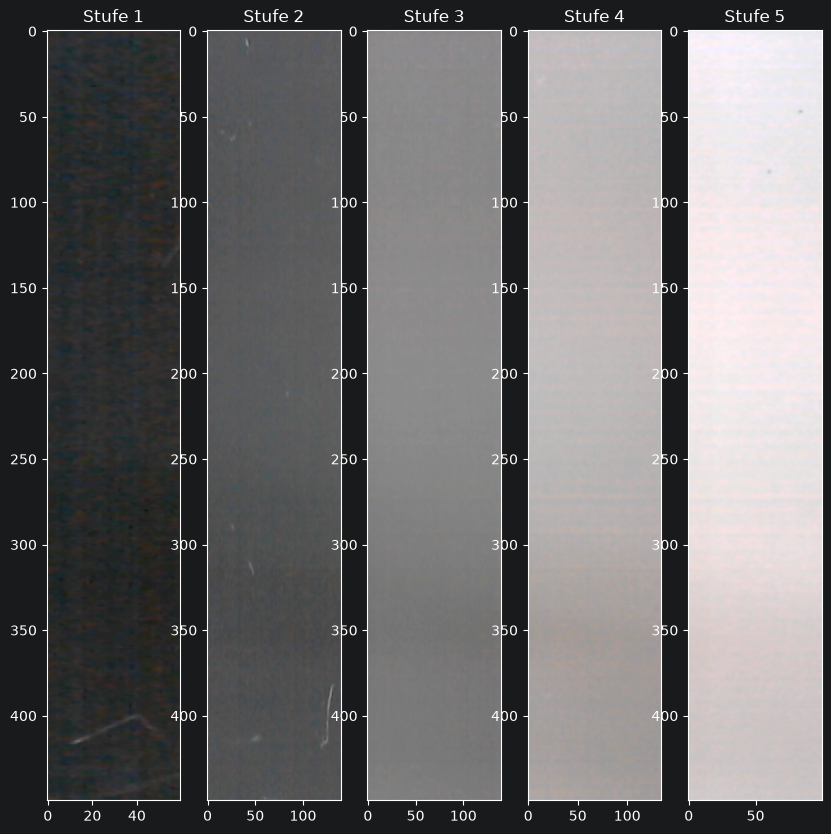

In [163]:
stufe1 = gray[0:450,20:80]
stufe2 = gray[0:450,100:240]
stufe3 = gray[0:450,250:390]
stufe4 = gray[0:450,395:530]
stufe5 = gray[0:450,540:650]

fig, ax = plt.subplots(1,5,figsize = (10,10))
stufen = [stufe1, stufe2, stufe3, stufe4, stufe5]

for i in range(len(stufen)):
    ax[i].imshow(stufen[i], cmap = "gray", aspect = "auto")
    ax[i].set_title(f"Stufe {i + 1}")
plt.show()

Berechnung von Mittelwert und Standardabweichung

In [164]:
for i in range(len(stufen)):
    mittelwert = np.mean(stufen[i])
    std = np.std(stufen[i])
    print(f"Stufe {i + 1}: Mittelwert = {mittelwert:.2f}, Std = {std:.2f}")

Stufe 1: Mittelwert = 42.43, Std = 5.80
Stufe 2: Mittelwert = 86.27, Std = 6.60
Stufe 3: Mittelwert = 131.69, Std = 8.49
Stufe 4: Mittelwert = 177.86, Std = 13.03
Stufe 5: Mittelwert = 226.83, Std = 15.96


AUFGABE 2: AUFNAHME EINES DUNKELBILDES

Einlesen der Dunkelbilder

In [165]:
dark = []
for i in range(1,11):
    bild = cv2.imread(f"data/Dunkelbild/dark{i}.png")
    dark.append(bild)

Umwandlung in Grauwertbilder und Double

In [166]:
dark_gray = []
for bild in dark:
    gray_bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    gray_bild = gray_bild.astype(np.double)
    dark_gray.append(gray_bild)

print(len(dark_gray))

10


Berechnung des pixelweisen Mittelwertes

In [167]:
dark_bild = np.mean(dark_gray, axis = 0)
print(dark_bild.shape)
print(dark_bild.dtype)

np.save("data/dark_bild.npy", dark_bild)

(480, 640)
float64


Kontrastmaximierte Darstellung des Dunkelbildes

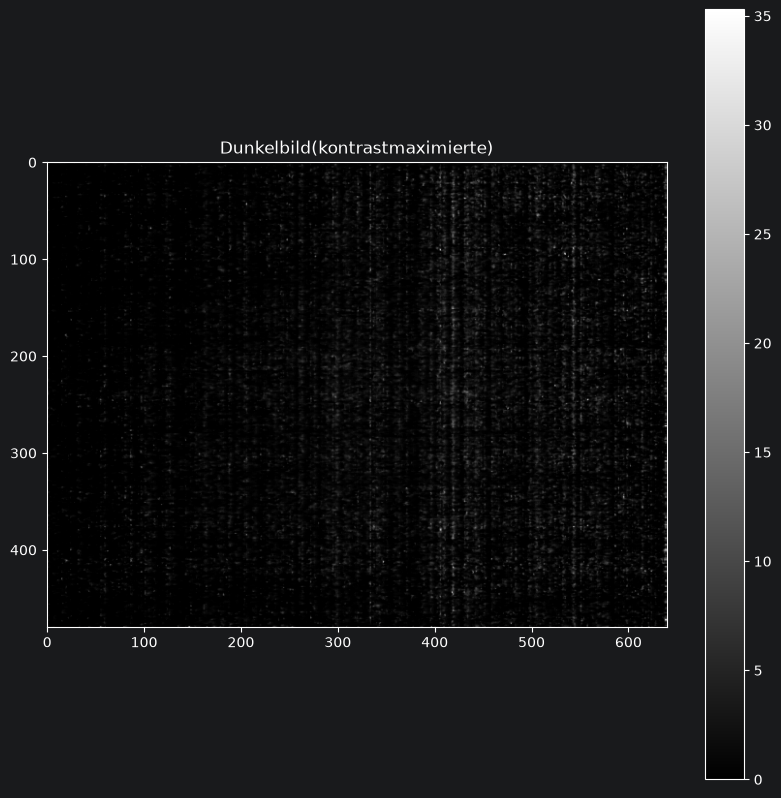

In [168]:
plt.figure(figsize = (10,10))
plt.imshow(dark_bild, cmap = "gray")
plt.title("Dunkelbild(kontrastmaximierte)")
plt.colorbar()
plt.show()

Dunkelbild-Korrektur

In [181]:
def dunkelbild_korrektur(eingabebild):
    np.load("data/dark_bild.npy")
    bild = cv2.imread(eingabebild)
    bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    bild = bild.astype(np.double)

    korrigiert = bild - dark_bild

    np.save("data/korrigiert.npy", korrigiert)
    return korrigiert

Test

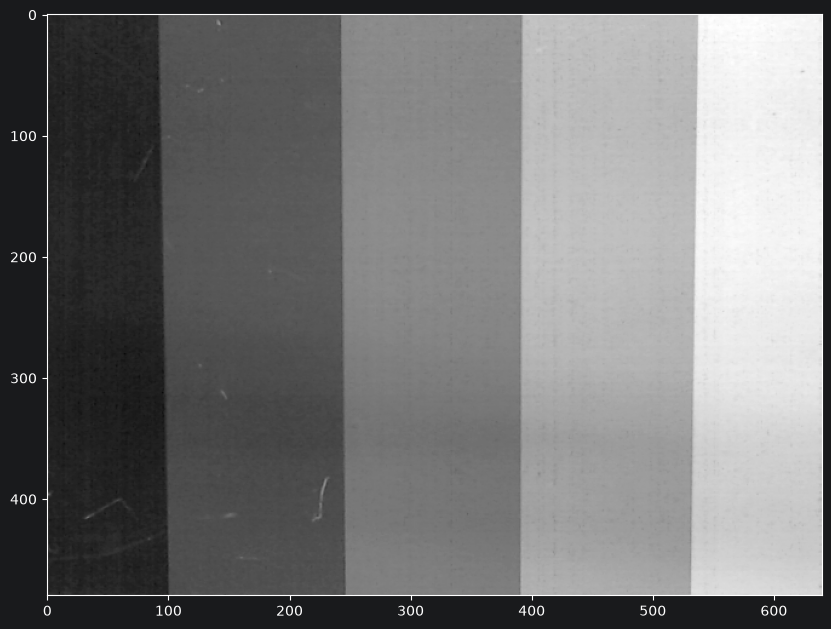

In [182]:
test = dunkelbild_korrektur("data/Grauwertkeil/gray.png")
bild = np.load("data/korrigiert.npy")
plt.figure(figsize = (10,10))
plt.imshow(bild, cmap = "gray")
plt.show()

In [183]:
original = cv2.imread("data/Grauwertkeil/gray.png")
original = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

korrigiert = np.load("data/korrigiert.npy")

print("Original:", np.mean(original))
print("Korrigiert:", np.mean(korrigiert))

Original: 132.61744791666666
Korrigiert: 131.58610546875


AUFGABE 3: AUFNAHME EINES WEISSESBILDES

Einlesen der Weissenbilder

In [172]:
white = []
for i in range(1,11):
    bild = cv2.imread(f"data/Weissbild/white{i}.png")
    white.append(bild)

print(len(white))

10


Umwandlung in Grauwertbilder und Double

In [173]:
white_gray = []
for bild in white:
    gray_bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    gray_bild = gray_bild.astype(np.double)
    white_gray.append(gray_bild)

print(len(white_gray))

10


Berechnung des Mittelwertebilders

In [174]:
white_bild = np.mean(white_gray, axis = 0)
print(white_bild.shape)
print(white_bild.dtype)

(480, 640)
float64


Substraktion des Dunkelbildes

In [175]:
white_bild = white_bild - dark_bild
np.save("data/white_bild.npy", white_bild)

Darstellung und Speicherung des Weißbildes

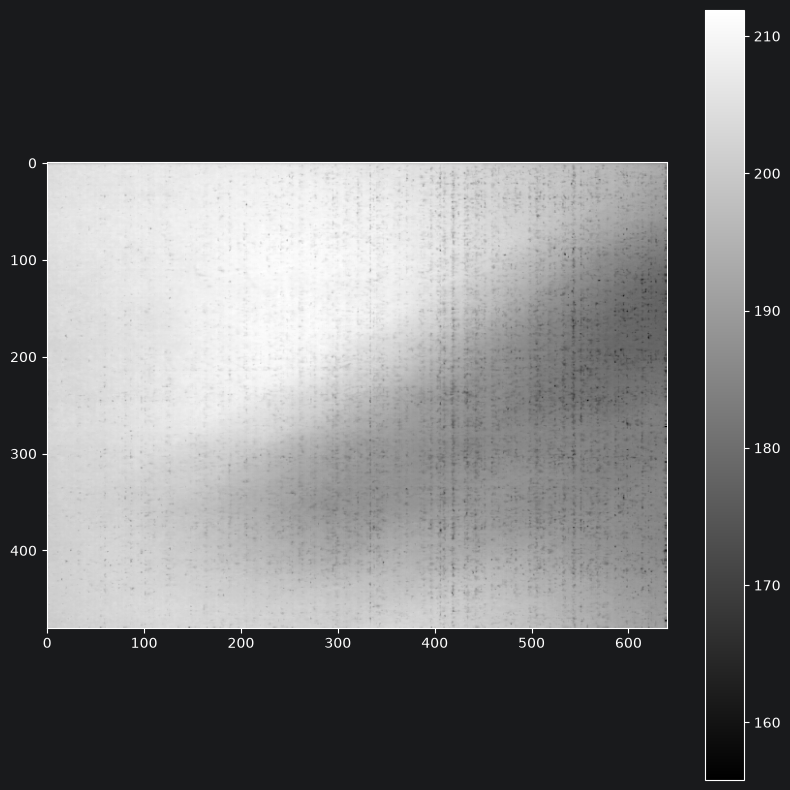

In [176]:
plt.figure(figsize = (10,10))
plt.imshow(white_bild, cmap = "gray")
plt.colorbar()
plt.show()

Normierung des Weissbildes

In [178]:
white_norm = white_bild / np.mean(white_bild)
print(np.mean(white_norm))

1.0000000000000002


Erweiterung der Bildkorrektur

In [184]:
def bild_korrektur(eingabebild):
    np.load("data/dark_bild.npy")
    bild = cv2.imread(eingabebild)
    bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    bild = bild.astype(np.double)

    korrigiert = (bild - dark_bild) / white_norm


    np.save("data/korrigiert2.npy", korrigiert)
    return korrigiert

Test

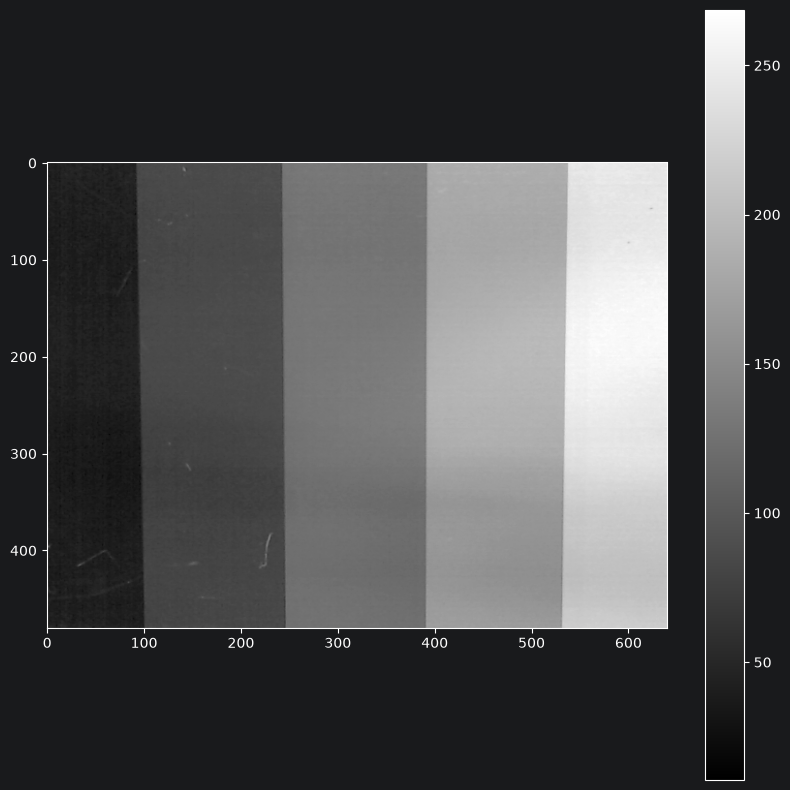

In [185]:
test = bild_korrektur("data/Grauwertkeil/gray.png")
plt.figure(figsize = (10,10))
plt.imshow(test, cmap = "gray")
plt.colorbar()
plt.show()


In [186]:
original = cv2.imread("data/Grauwertkeil/gray.png")
original = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

korrigiert = np.load("data/korrigiert2.npy")

print("Original:", np.mean(original))
print("Korrigiert:", np.mean(korrigiert))

Original: 132.61744791666666
Korrigiert: 133.7414793729953
